In [ ]:
import matplotlib.pyplot as plt
import os
import tensorflow as tf

In [ ]:
!pip install  tensorflow

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
dataset_path = "/content/drive/MyDrive/driving_dataset/stage1"

os.listdir(dataset_path)

['val', 'train']

In [ ]:
train_path = dataset_path + "/train"
val_path = dataset_path + "/val"

print("Train Classes:")
print(os.listdir(train_path))

print("\nValidation Classes:")
print(os.listdir(val_path))

Train Classes:
['one_hand', 'both_hands', 'no_hands']

Validation Classes:
['one_hand', 'no_hands', 'both_hands']


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 3624 files belonging to 3 classes.
Found 1052 files belonging to 3 classes.


In [ ]:
class_names = train_dataset.class_names

print(class_names)

['both_hands', 'no_hands', 'one_hand']


In [ ]:
for images, labels in train_dataset.take(1):
    print(images.shape)
    print(labels.shape)

(32, 224, 224, 3)
(32,)


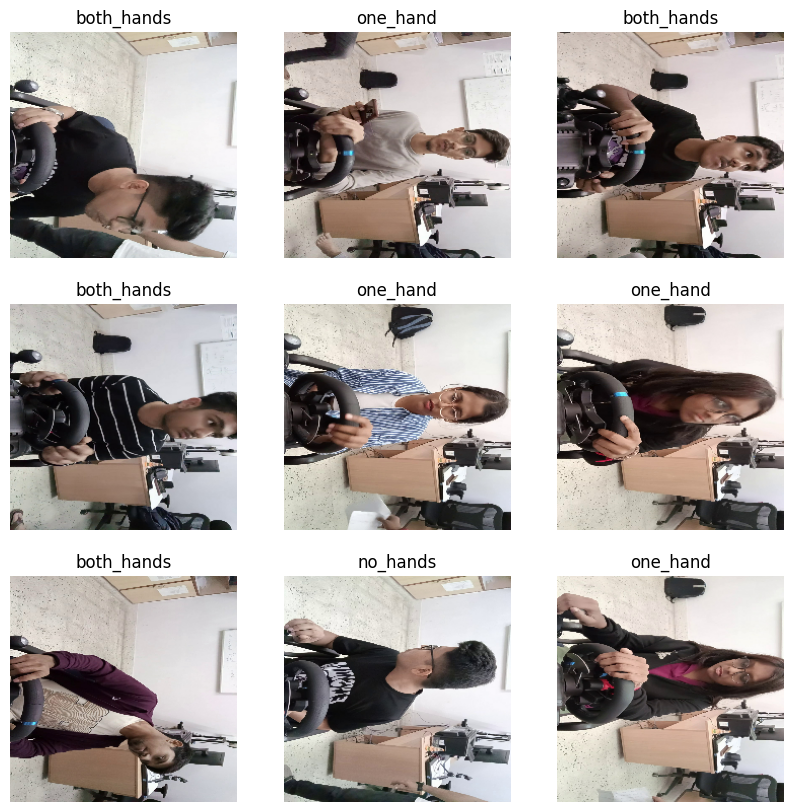

In [ ]:
plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):

    for i in range(9):

        ax = plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

In [ ]:
train_dataset = train_dataset.map(
    lambda x, y: (tf.image.rot90(x, k=3), y)
)

val_dataset = val_dataset.map(
    lambda x, y: (tf.image.rot90(x, k=3), y)
)

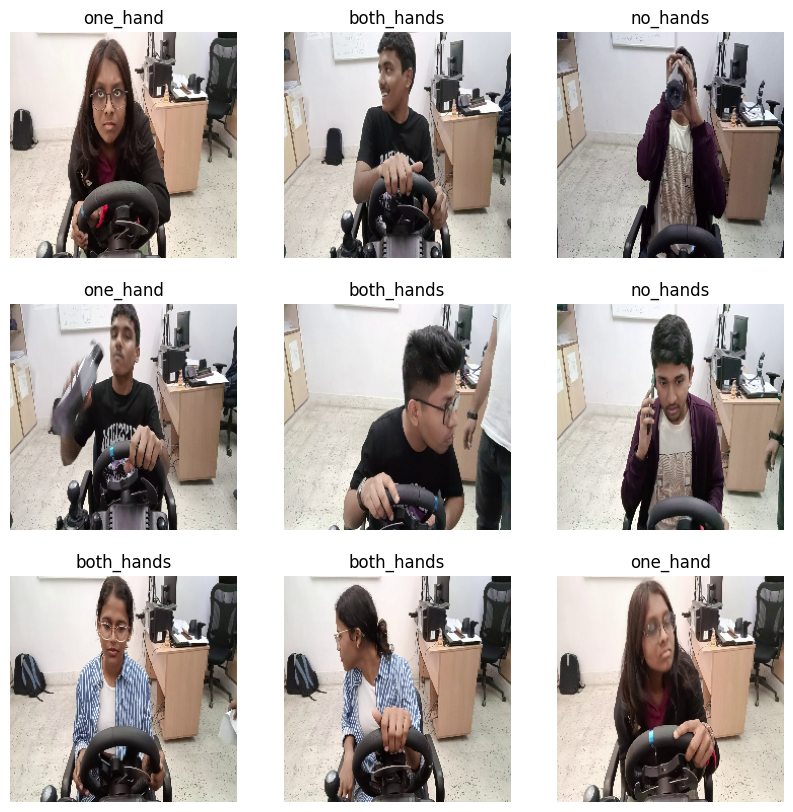

In [ ]:
plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):

    for i in range(9):

        ax = plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

# MODEL : **EFFICIENTNETB0**

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

In [ ]:
efficientnet_base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

In [ ]:
efficientnet_base_model.trainable = False

In [ ]:
efficientnet_model = models.Sequential([

    efficientnet_base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(3, activation='softmax')

])

In [ ]:
efficientnet_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
efficientnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/driving_dataset/best_stage1_model_v2.keras",
    save_best_only=True,
    monitor='val_accuracy'
)

earlystop = tf.keras.callbacks.EarlyStopping(
    patience=3,
    restore_best_weights=True
)

In [ ]:
efficientnet_model_history = efficientnet_model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=20,

    callbacks=[checkpoint, earlystop]

)

Epoch 1/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 664s 6s/step - accuracy: 0.7205 - loss: 0.6412 - val_accuracy: 0.7605 - val_loss: 0.4969
Epoch 2/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 63s 550ms/step - accuracy: 0.8458 - loss: 0.4063 - val_accuracy: 0.8774 - val_loss: 0.3430
Epoch 3/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 67s 584ms/step - accuracy: 0.8783 - loss: 0.3328 - val_accuracy: 0.8470 - val_loss: 0.3308
Epoch 4/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 61s 535ms/step - accuracy: 0.9001 - loss: 0.2854 - val_accuracy: 0.9144 - val_loss: 0.2611
Epoch 5/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 62s 537ms/step - accuracy: 0.9092 - loss: 0.2601 - val_accuracy: 0.9316 - val_loss: 0.2250
Epoch 6/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 61s 532ms/step - accuracy: 0.9216 - loss: 0.2384 - val_accuracy: 0.9163 - val_loss: 0.2235
Epoch 7/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 82s 533ms/step - accuracy: 0.9183 - loss: 0.2243 - val_accuracy: 0.9468 - val_loss: 0.1820
Epoch 8/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 59s 518ms/step - accuracy: 0.9227 - loss: 0.2

In [ ]:
import json

with open("/content/drive/MyDrive/driving_dataset/history_stage1_v2.json", "w") as f:

    json.dump(efficientnet_model_history.history, f)

In [ ]:
efficientnet_model.save(
    "/content/drive/MyDrive/driving_dataset/best_stage1_model_v2.keras"
)

In [ ]:
acc = efficientnet_model_history.history['accuracy']
val_acc = efficientnet_model_history.history['val_accuracy']

loss = efficientnet_model_history.history['loss']
val_loss = efficientnet_model_history.history['val_loss']

epochs_range = range(len(acc))

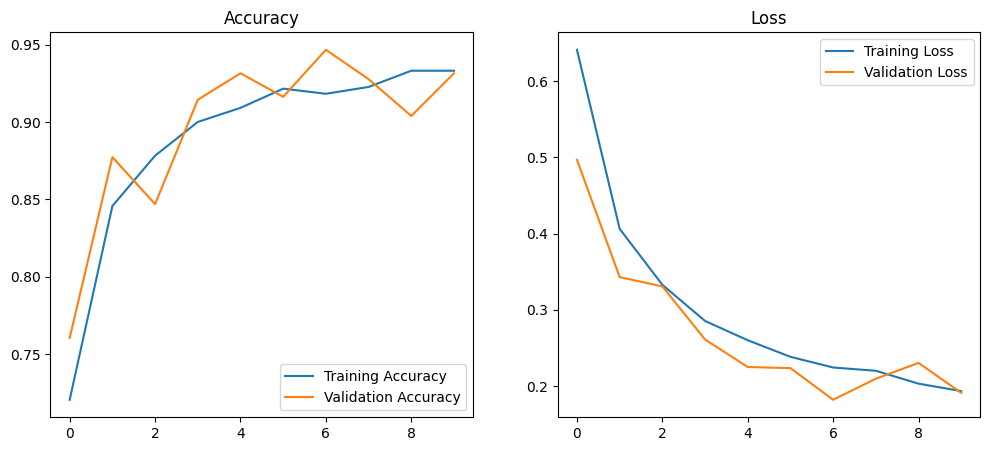

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()

In [ ]:
plt.savefig(
    "/content/drive/MyDrive/driving_dataset/accuracy_loss_plot_v2.png"
)

In [ ]:
y_true = []
y_pred = []

In [ ]:
for images, labels in val_dataset:

    predictions = efficientnet_model.predict(images)

    predicted_labels = tf.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())

    y_pred.extend(predicted_labels.numpy())

1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [ ]:
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[424   0   5]
 [  0 205  10]
 [  3  11 394]]


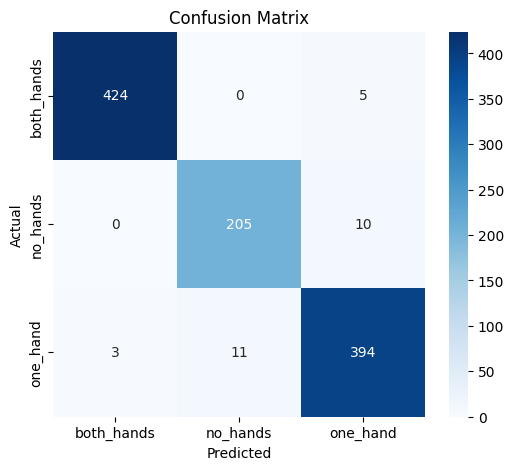

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

  both_hands       0.99      0.99      0.99       429
    no_hands       0.95      0.95      0.95       215
    one_hand       0.96      0.97      0.96       408

    accuracy                           0.97      1052
   macro avg       0.97      0.97      0.97      1052
weighted avg       0.97      0.97      0.97      1052



# ResNet50 Model

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

In [ ]:
resnet_base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
resnet_base_model.trainable = False

In [ ]:
resnet_model = models.Sequential([

    resnet_base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(3, activation='softmax')

])

In [ ]:
resnet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
resnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/driving_dataset/best_resnet50_stage1.keras",
    save_best_only=True,
    monitor='val_accuracy'
)

earlystop = tf.keras.callbacks.EarlyStopping(
    patience=3,
    restore_best_weights=True
)

In [ ]:
resnet_history = resnet_model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=20,

    callbacks=[checkpoint, earlystop]

)

Epoch 1/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 91s 646ms/step - accuracy: 0.6749 - loss: 0.8151 - val_accuracy: 0.8080 - val_loss: 0.4711
Epoch 2/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 63s 546ms/step - accuracy: 0.8295 - loss: 0.4427 - val_accuracy: 0.8812 - val_loss: 0.3200
Epoch 3/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 63s 544ms/step - accuracy: 0.8656 - loss: 0.3397 - val_accuracy: 0.9030 - val_loss: 0.2689
Epoch 4/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 86s 585ms/step - accuracy: 0.8836 - loss: 0.2902 - val_accuracy: 0.8222 - val_loss: 0.4251
Epoch 5/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 61s 535ms/step - accuracy: 0.8971 - loss: 0.2601 - val_accuracy: 0.9325 - val_loss: 0.1937
Epoch 6/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 81s 530ms/step - accuracy: 0.9145 - loss: 0.2428 - val_accuracy: 0.9011 - val_loss: 0.2197
Epoch 7/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 60s 525ms/step - accuracy: 0.9236 - loss: 0.2171 - val_accuracy: 0.9259 - val_loss: 0.1995
Epoch 8/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 69s 603ms/step - accuracy: 0.9294 - loss: 0

In [ ]:
import json

with open("/content/drive/MyDrive/driving_dataset/history_resnet50_stage1.json", "w") as f:

    json.dump(resnet_history.history, f)

In [ ]:
resnet_model.save(
    "/content/drive/MyDrive/driving_dataset/best_resnet50_stage1.keras"
)

In [ ]:
acc = resnet_history.history['accuracy']
val_acc = resnet_history.history['val_accuracy']

loss = resnet_history.history['loss']
val_loss = resnet_history.history['val_loss']

epochs_range = range(len(acc))

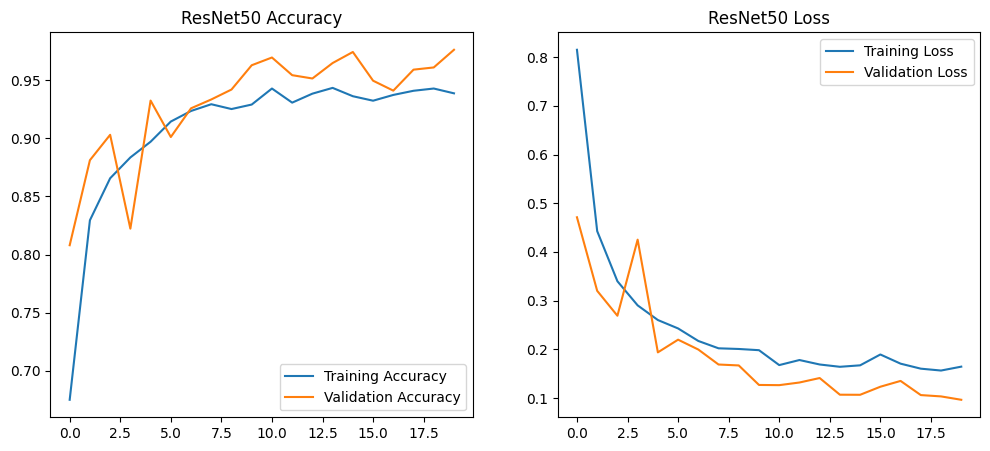

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('ResNet50 Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('ResNet50 Loss')

plt.show()

In [ ]:
plt.savefig(
    "/content/drive/MyDrive/driving_dataset/resnet50_accuracy_loss_plot.png"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
y_true_res = []
y_pred_res = []

for images, labels in val_dataset:

    predictions = resnet_model.predict(images)

    predicted_labels = tf.argmax(predictions, axis=1)

    y_true_res.extend(labels.numpy())

    y_pred_res.extend(predicted_labels.numpy())

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 394ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [ ]:
cm = confusion_matrix(y_true_res, y_pred_res)

print(cm)

[[427   1   1]
 [  3 198  14]
 [  6   0 402]]


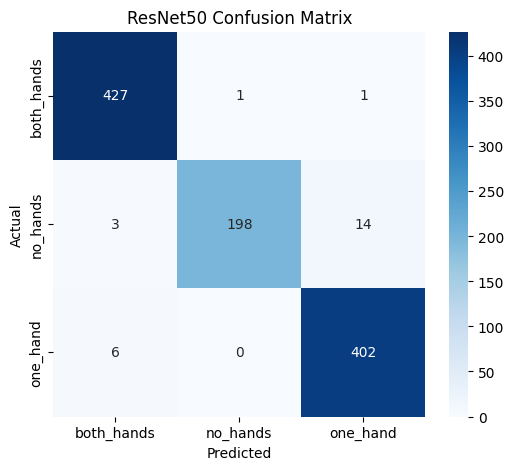

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet50 Confusion Matrix")

plt.show()

In [ ]:
plt.savefig(
    "/content/drive/MyDrive/driving_dataset/resnet50_confusion_matrix.png"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
print(classification_report(
    y_true_res,
    y_pred_res,
    target_names=class_names
))

              precision    recall  f1-score   support

  both_hands       0.98      1.00      0.99       429
    no_hands       0.99      0.92      0.96       215
    one_hand       0.96      0.99      0.97       408

    accuracy                           0.98      1052
   macro avg       0.98      0.97      0.97      1052
weighted avg       0.98      0.98      0.98      1052

